<a href="https://colab.research.google.com/github/Baonguyen2414l/cmu-movie-recommender/blob/Baodev/notebooks/01_eda_and_preprocess.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#KHẢO SÁT VÀ TIỀN XỬ LÝ DỮ LIỆU (CMU MOVIE SUMMARY CORPUS)
**Mục tiêu:**
1. Tải dữ liệu gốc `MovieSummaries.tar.gz` từ Đại học Carnegie Mellon.
2. Ghép nối `plot_summaries.txt` và `movie.metadata.tsv` theo `movie_id`.
3. Khảo sát phân bố độ dài tóm tắt và tần suất thể loại (EDA).
4. Lọc **Top 15 thể loại phổ biến** và cố định **5.000 phim hợp lệ**.
5. Làm sạch văn bản (`raw_text` và `clean_text` - không chứa nhãn thể loại) và chia tập **Train / Val / Test (70/15/15)** theo phân tầng đa nhãn.

## 1. Kết nối Google Drive và Tải dữ liệu gốc


In [11]:
# 1. Cài đặt  thư viện chia dữ liệu đa nhãn (Multi-label Stratification)
!pip install -q iterative-stratification

# 2. Thư viện hệ thống & chuẩn Python (Standard Libraries)
import os
import re
import json
import pickle
from collections import Counter

# 3. Thư viện xử lý dữ liệu & vẽ biểu đồ (Third-party Libraries)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 4. Thư viện NLP, Machine Learning & Google Colab
import nltk
from nltk.corpus import stopwords
from sklearn.preprocessing import MultiLabelBinarizer
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from google.colab import drive

In [12]:


# 1. Kết nối Google Drive
drive.mount('/content/drive')

# Tạo thư mục dùng chung trên Google Drive
SAVE_DIR = '/content/drive/MyDrive/MovieRec_Shared_Data/processed'
os.makedirs(SAVE_DIR, exist_ok=True)
print(f"Đã sẵn sàng lưu dữ liệu tại: {SAVE_DIR}")
# 2. Tải và giải nén bộ dữ liệu CMU Movie Summary trực tiếp trên Colab
if not os.path.exists('MovieSummaries'):
    !wget -q https://www.cs.cmu.edu/~ark/personas/data/MovieSummaries.tar.gz
    !tar -xzf MovieSummaries.tar.gz
    print("Đã tải và giải nén thành công dữ liệu CMU MovieSummaries!")
else:
    print("Dữ liệu đã tồn tại.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Đã sẵn sàng lưu dữ liệu tại: /content/drive/MyDrive/MovieRec_Shared_Data/processed
Dữ liệu đã tồn tại.


## 2. Đọc dữ liệu, Ghép bảng và Xử lý dữ liệu thiếu/trùng
* Đọc `plot_summaries.txt` lấy mã phim và nội dung tóm tắt.
* Đọc `movie.metadata.tsv` lấy mã phim, tên phim, năm phát hành và giải mã chuỗi JSON thể loại.
* Ghép (`Inner Join`) hai bảng theo `movie_id`, loại bỏ dòng trùng lặp hoặc thiếu thông tin.

In [13]:

# 1. Đọc file tóm tắt phim (plot_summaries.txt)
summaries_path = 'MovieSummaries/plot_summaries.txt'
df_plots = pd.read_csv(summaries_path, sep='\t', header=None, names=['movie_id', 'summary'])

# 2. Đọc file thông tin phim (movie.metadata.tsv)
meta_path = 'MovieSummaries/movie.metadata.tsv'
df_meta = pd.read_csv(meta_path, sep='\t', header=None, usecols=[0, 2, 3, 8],
                      names=['movie_id', 'title', 'release_date', 'genres_json'])

# Hàm giải mã JSON thể loại thành danh sách tên thể loại
def parse_genres(json_str):
    if pd.isna(json_str):
        return []
    try:
        genre_dict = json.loads(json_str)
        return list(genre_dict.values())
    except:
        return []

df_meta['genres_list'] = df_meta['genres_json'].apply(parse_genres)

# 3. Ghép 2 bảng theo movie_id
df = pd.merge(df_meta[['movie_id', 'title', 'release_date', 'genres_list']], df_plots, on='movie_id', how='inner')

# 4. Xử lý dữ liệu thiếu và trùng lặp
print(f"Tổng số phim sau khi ghép bảng: {len(df)}")
df = df.dropna(subset=['title', 'summary']).copy()
df = df.drop_duplicates(subset=['movie_id']).copy()
df = df.drop_duplicates(subset=['title', 'summary']).copy()

# Loại bỏ các phim không có thể loại nào
df = df[df['genres_list'].map(len) > 0].reset_index(drop=True)
print(f"Số phim hợp lệ (có đủ tên, tóm tắt và ít nhất 1 thể loại): {len(df)}")
df.head(3)

Tổng số phim sau khi ghép bảng: 42204
Số phim hợp lệ (có đủ tên, tóm tắt và ít nhất 1 thể loại): 41788


,movie_id,title,release_date,genres_list,summary
0,975900,Ghosts of Mars,2001-08-24,"[Thriller, Science Fiction, Horror, Adventure,...","Set in the second half of the 22nd century, th..."
1,9363483,White Of The Eye,1987,"[Thriller, Erotic thriller, Psychological thri...",A series of murders of rich young women throug...
2,261236,A Woman in Flames,1983,[Drama],"Eva, an upper class housewife, becomes frustra..."


## 3. Khảo sát dữ liệu (EDA) và Lọc phạm vi 5.000 phim
* Tính độ dài văn bản (số từ), loại bỏ các bản tóm tắt quá ngắn (< 50 từ) hoặc quá dài (> 1.500 từ).
* Loại bỏ các nhãn thể loại mang tính định dạng kỹ thuật (*Short Film, Black-and-white, Silent film, Indie, World cinema...*), giữ lại **Top 15 thể loại nội dung phổ biến nhất**.
* Lọc và lấy mẫu cố định **5.000 phim** để đảm bảo tốc độ thực nghiệm đồng nhất giữa 4 phương pháp.

Số phim có độ dài tóm tắt từ 50 - 1500 từ: 37089

Top 15 thể loại được chọn:
 ['Drama', 'Comedy', 'Romance Film', 'Thriller', 'Action', 'Crime Fiction', 'Horror', 'Action/Adventure', 'Family Film', 'Adventure', 'Romantic drama', 'Animation', 'Musical', 'Science Fiction', 'Romantic comedy']
Số phim có ít nhất 1 thể loại thuộc Top 15: 33429
Đã chốt danh sách thực nghiệm: 5000 phim.


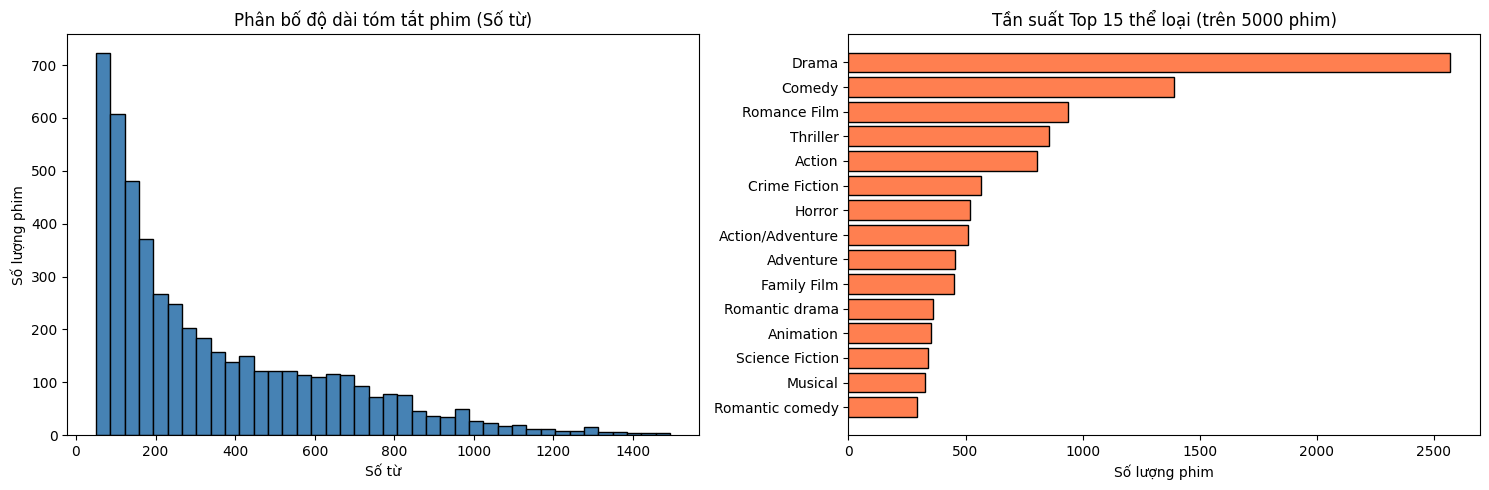

In [14]:


# 1. Tính độ dài tóm tắt (số từ) và lọc độ dài hợp lý (50 -> 1500 từ)
df['word_count'] = df['summary'].apply(lambda x: len(str(x).split()))
df = df[(df['word_count'] >= 50) & (df['word_count'] <= 1500)].reset_index(drop=True)
print(f"Số phim có độ dài tóm tắt từ 50 - 1500 từ: {len(df)}")

# 2. Thống kê tần suất thể loại và loại bỏ các nhãn không mang tính nội dung cốt truyện
noise_genres = {
    'Short Film', 'Black-and-white', 'Silent film', 'Indie', 'World cinema',
    'Bollywood', 'Film adaptation', 'Pre-Code', 'B-movie', 'Cult', 'Filipino Movies',
    'Japanese Movies', 'Chinese Movies', 'Ensemble Film'
}

all_genres = [g for sublist in df['genres_list'] for g in sublist if g not in noise_genres]
genre_counts = Counter(all_genres)

# Chọn Top 15 thể loại phổ biến nhất
TOP_K_GENRES = 15
top_genres = [g for g, count in genre_counts.most_common(TOP_K_GENRES)]
top_genres_set = set(top_genres)
print(f"\nTop {TOP_K_GENRES} thể loại được chọn:\n", top_genres)

# Giữ lại các nhãn thuộc Top 15 cho mỗi phim
df['filtered_genres'] = df['genres_list'].apply(lambda gl: [g for g in gl if g in top_genres_set])
df = df[df['filtered_genres'].map(len) > 0].reset_index(drop=True)
print(f"Số phim có ít nhất 1 thể loại thuộc Top {TOP_K_GENRES}: {len(df)}")

# 3. Cố định đúng 5.000 phim cho đồ án (Random seed = 42 để kết quả tái lập 100%)
SAMPLE_SIZE = 5000
if len(df) > SAMPLE_SIZE:
    df = df.sample(n=SAMPLE_SIZE, random_state=42).reset_index(drop=True)
print(f"Đã chốt danh sách thực nghiệm: {len(df)} phim.")

# 4. Vẽ biểu đồ EDA (Lưu ảnh để đưa vào Slide/Báo cáo)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Biểu đồ 1: Phân bố độ dài tóm tắt
axes[0].hist(df['word_count'], bins=40, color='steelblue', edgecolor='black')
axes[0].set_title('Phân bố độ dài tóm tắt phim (Số từ)')
axes[0].set_xlabel('Số từ')
axes[0].set_ylabel('Số lượng phim')

# Biểu đồ 2: Phân bố Top 15 thể loại trong 5.000 phim
sample_genre_counts = Counter([g for sublist in df['filtered_genres'] for g in sublist])
genres_sorted = sorted(sample_genre_counts.items(), key=lambda x: x[1])
axes[1].barh([x[0] for x in genres_sorted], [x[1] for x in genres_sorted], color='coral', edgecolor='black')
axes[1].set_title(f'Tần suất Top {TOP_K_GENRES} thể loại (trên {SAMPLE_SIZE} phim)')
axes[1].set_xlabel('Số lượng phim')

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/eda_overview.png", dpi=150)
plt.show()

## 4. Làm sạch văn bản (Text Cleaning)
* Tạo cột `raw_text`: Chỉ chuẩn hóa khoảng trắng, giữ nguyên ngữ cảnh câu cho **Sentence Transformer**.
* Tạo cột `clean_text`: Chuyển chữ thường, xóa ký tự đặc biệt/chữ số và loại bỏ từ dừng (stopwords) cho **TF-IDF, Doc2Vec, TextCNN**.
* **Đảm bảo:** Không ghép tên thể loại vào văn bản đầu vào.

In [15]:

nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

def make_raw_text(text):
    # Chỉ xóa khoảng trắng thừa, giữ nguyên dấu câu cho Sentence Transformer
    return re.sub(r'\s+', ' ', str(text)).strip()

def make_clean_text(text):
    # Chuyển chữ thường, chỉ giữ lại chữ cái a-z, xóa stopwords
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = [w for w in text.split() if w not in stop_words and len(w) > 2]
    return ' '.join(tokens)

df['raw_text'] = df['summary'].apply(make_raw_text)
df['clean_text'] = df['summary'].apply(make_clean_text)

# Đảm bảo sau khi làm sạch không có chuỗi rỗng
df = df[df['clean_text'].str.len() > 20].reset_index(drop=True)
print("Ví dụ so sánh trước và sau khi làm sạch:")
print("- RAW  :", df.loc[0, 'raw_text'][:150], "...")
print("- CLEAN:", df.loc[0, 'clean_text'][:150], "...")

Ví dụ so sánh trước và sau khi làm sạch:
- RAW  : At a manor in Sarajevo, Ra's al Ghul ruefully realizes his mistake in allying himself with the Joker, while his assistant informs him that the Joker h ...
- CLEAN: manor sarajevo ghul ruefully realizes mistake allying joker assistant informs joker captured robin warehouse joker brutally beats robin crowbar batman ...


## 5. Mã hóa nhãn thể loại, Chia tập Train/Val/Test (70/15/15) và Lưu trữ
* Dùng `MultiLabelBinarizer` chuyển danh sách thể loại sang vector nhị phân 15 chiều.
* Dùng `MultilabelStratifiedShuffleSplit` để chia **70% Train - 15% Validation - 15% Test** sao cho tỷ lệ các thể loại đồng đều ở cả 3 tập.
* Lưu `movies_catalog.csv` và bộ mã hóa `mlb_genres.pkl` vào Google Drive.
* Chia tập Train / Val / Test (70/15/15)

In [16]:


# 1. Mã hóa nhãn thể loại sang nhị phân (Multi-hot encoding)
mlb = MultiLabelBinarizer(classes=top_genres)
Y = mlb.fit_transform(df['filtered_genres'])

# 2. Chia 70% Train và 30% Temp (Val + Test)
msss1 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(msss1.split(df, Y))

# 3. Chia đôi 30% Temp thành 15% Val và 15% Test
msss2 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_rel_idx, test_rel_idx = next(msss2.split(df.iloc[temp_idx], Y[temp_idx]))

val_idx = temp_idx[val_rel_idx]
test_idx = temp_idx[test_rel_idx]

# Gán nhãn split vào bảng dữ liệu
df['split'] = 'train'
df.loc[val_idx, 'split'] = 'val'
df.loc[test_idx, 'split'] = 'test'

# Chuyển list thể loại thành chuỗi ngăn cách bởi dấu "|" để lưu CSV không bị lỗi định dạng
df['genres_str'] = df['filtered_genres'].apply(lambda gl: '|'.join(gl))

print("Thống kê số lượng phim theo từng tập:")
print(df['split'].value_counts())

# 4. Lưu các file thành phẩm lên Google Drive  để dùng chung
cols_to_save = ['movie_id', 'title', 'release_date', 'genres_str', 'word_count', 'raw_text', 'clean_text', 'split']
catalog_path = f"{SAVE_DIR}/movies_catalog.csv"
df[cols_to_save].to_csv(catalog_path, index=False)

# Lưu ma trận nhãn nhị phân Y và bộ MultiLabelBinarizer (dùng cho TextCNN và Evaluation)
np.save(f"{SAVE_DIR}/genre_labels.npy", Y)
with open(f"{SAVE_DIR}/mlb_genres.pkl", "wb") as f:
    pickle.dump(mlb, f)

print(f"\nHOÀN TẤT BƯỚC 1! Đã lưu thành công:")
print(f"1. {catalog_path}")
print(f"2. {SAVE_DIR}/genre_labels.npy (Kích thước: {Y.shape})")
print(f"3. {SAVE_DIR}/mlb_genres.pkl")

Thống kê số lượng phim theo từng tập:
split
train    3500
test      763
val       737
Name: count, dtype: int64

HOÀN TẤT BƯỚC 1! Đã lưu thành công:
1. /content/drive/MyDrive/MovieRec_Shared_Data/processed/movies_catalog.csv
2. /content/drive/MyDrive/MovieRec_Shared_Data/processed/genre_labels.npy (Kích thước: (5000, 15))
3. /content/drive/MyDrive/MovieRec_Shared_Data/processed/mlb_genres.pkl
